[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aprendizaje-automatico-dc-uba-ar/material/blob/main/notebooks/notebook_09_redes_neuronales-published.ipynb)

# Redes neuronales


Vamos nuevamente a trabajar con los datos de `iris` para entrenar (y antes construir) una Red Neuronal.

In [377]:
from sklearn.preprocessing import LabelEncoder
from sklearn.datasets import load_iris
import numpy as np
import matplotlib.pyplot as plt

import torch

def get_data() -> tuple[np.ndarray, np.ndarray]:
    """
    Cargar el dataset Iris.

    Returns
    -------
    X : np.ndarray of shape (n_samples, n_features)
        Features de cada observación (150 x 4).
    y : np.ndarray of shape (n_samples,)
        Etiquetas codificadas como enteros 0, 1, 2.
    """
    dataset = load_iris()
    X = dataset["data"]
    y = dataset["target"]
    y = LabelEncoder().fit_transform(y)
    return np.array(X), np.array(y)

X, y = get_data()
X.shape, y.shape

((150, 4), (150,))

In [378]:
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.long)

La propuesta es empezar por el esqueleto de las 2 clases que usaremos para esta tarea e ir implementado los métodos a medida que avancemos.

Al final de este notebook se encuentran ambas clases completas. Pueden copiar el código desde allí mismo o implementarlo. La idea es que en cada avance podamos comprender la parte del proceso que estamos realizando, por lo cual se recomienda seguir la guia propuesta e ir completando sólo lo que es necesario para cada punto.

In [379]:
class Capa:
    def __init__(self, neuronas: int) -> None:
        """
        Parameters
        ----------
        neuronas : int
            Cantidad de neuronas (dimensión de salida) de la capa.
        """
        self.neuronas = neuronas

    def forward(
        self,
        inputs: torch.Tensor,
        weights: torch.Tensor,
        bias: torch.Tensor,
        activation: str,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Forward Propagation de la capa: Z = inputs @ weights + bias, A = f(Z).

        Parameters
        ----------
        inputs : torch.Tensor of shape (n_samples, input_dim)
            Activaciones de la capa anterior (o los datos, en la primera capa).
        weights : torch.Tensor of shape (input_dim, output_dim)
            Matriz de pesos W de la capa.
        bias : torch.Tensor of shape (1, output_dim)
            Vector de bias b de la capa.
        activation : {'relu', 'softmax'}
            Función de activación a aplicar sobre Z.

        Returns
        -------
        A : torch.Tensor of shape (n_samples, output_dim)
            Activación de la capa, f(Z).
        Z : torch.Tensor of shape (n_samples, output_dim)
            Pre-activación, se guarda para el backward.
        """
        Z = inputs @ weights + bias
        activation_f = self.relu if activation == 'relu' else self.softmax
        return activation_f(Z), Z

    def relu(self, inputs: torch.Tensor) -> torch.Tensor:
        """
        ReLU: función de activación, max(0, x) elemento a elemento.

        Parameters
        ----------
        inputs : torch.Tensor
            Tensor de cualquier shape (típicamente Z).

        Returns
        -------
        torch.Tensor
            Tensor de la misma shape con los valores negativos en 0.
        """
        return torch.maximum(torch.tensor(0.0), inputs)

    def softmax(self, inputs: torch.Tensor) -> torch.Tensor:
        """
        Softmax: función de activación, numéricamente estable (resta el máximo por fila).

        Parameters
        ----------
        inputs : torch.Tensor of shape (n_samples, n_classes)
            Logits de la capa de salida.

        Returns
        -------
        torch.Tensor of shape (n_samples, n_classes)
            Probabilidades por clase; cada fila suma 1.
        """
        shifted = inputs - torch.max(inputs, dim=1, keepdim=True).values
        exp_scores = torch.exp(shifted)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)
        return probs

    def backward(
        self,
        dA_curr: torch.Tensor,
        W_curr: torch.Tensor,
        Z_curr: torch.Tensor,
        A_prev: torch.Tensor,
        activation: str,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Backward Propagation de la capa.

        Parameters
        ----------
        dA_curr : torch.Tensor of shape (n_samples, output_dim)
            Gradiente de la loss respecto de la activación de esta capa.
            Para softmax, ya es dL/dZ (softmax + cross-entropy combinados).
        W_curr : torch.Tensor of shape (input_dim, output_dim)
            Pesos de la capa, con la misma orientación que en forward.
        Z_curr : torch.Tensor of shape (n_samples, output_dim)
            Pre-activación guardada en el forward.
        A_prev : torch.Tensor of shape (n_samples, input_dim)
            Entrada de la capa guardada en el forward.
        activation : {'relu', 'softmax'}
            Función de activación de la capa.

        Returns
        -------
        dA_prev : torch.Tensor of shape (n_samples, input_dim)
            Gradiente respecto de la entrada, se propaga a la capa anterior.
        dW : torch.Tensor of shape (input_dim, output_dim)
            Gradiente respecto de los pesos.
        db : torch.Tensor of shape (1, output_dim)
            Gradiente respecto del bias.
        """

        # Forward: Z = A_prev @ W + b, A = act(Z), L = loss, dX = dL/dX.

        # dZ = dL/dA * dA/dZ = dA ⊙ act'(Z)
        dZ = dA_curr if activation == 'softmax' else self.relu_derivative(dA_curr, Z_curr)

        # dW = dL/dZ * dZ/dW, con dZ/dW = A_prev  ->  A_prev.T @ dZ (suma sobre las muestras)
        dW = A_prev.T @ dZ

        # db = dL/dZ * dZ/db, con dZ/db = 1  ->  sumar dZ sobre las muestras
        db = torch.sum(dZ, dim=0, keepdim=True)

        # dA_prev = dL/dZ * dZ/dA_prev, con dZ/dA_prev = W  ->  dZ @ W.T
        # Es el dA que recibe la capa anterior en su backward
        dA_prev = dZ @ W_curr.T

        return dA_prev, dW, db

    def relu_derivative(self, dA: torch.Tensor, Z: torch.Tensor) -> torch.Tensor:
        """
        ReLU: gradiente de ReLU, dZ = dA * 1[Z > 0].

        Parameters
        ----------
        dA : torch.Tensor of shape (n_samples, output_dim)
            Gradiente de la loss respecto de la activación.
        Z : torch.Tensor of shape (n_samples, output_dim)
            Pre-activación de la capa.

        Returns
        -------
        torch.Tensor of shape (n_samples, output_dim)
            Gradiente de la loss respecto de Z.
        """
        dZ = dA.clone()
        dZ[Z <= 0] = 0
        return dZ

In [380]:
class RedNeuronal:
    def __init__(self, learning_rate: float = 0.01) -> None:
        """
        Parameters
        ----------
        learning_rate : float, default=0.01
            Tasa de aprendizaje usada en `_update`.
        """
        self.red = [] ## capas
        self.arquitectura = [] ## mapeo de entradas -> salidas
        self.pesos = [] ## W, b
        self.memoria = [] ## Z, A
        self.gradientes = [] ## dW, db
        self.lr = learning_rate

        self.compiled = False
        
    def add(self, capa: Capa) -> None:
        """
        Agregar capa a la red.

        Parameters
        ----------
        capa : Capa
            Capa a agregar al final de la red.
        """
        self.red.append(capa)
            
    def _compile(self, data: np.ndarray | torch.Tensor) -> None:
        """
        Inicializar la arquitectura.

        Parameters
        ----------
        data : np.ndarray or torch.Tensor of shape (n_samples, n_features)
            Datos de entrada; solo se usa n_features como input_dim de la primera capa.

        README: 
        Acá inicializamos la descripcion de la arquitectura en entrada-salida.
        Funciona solo para el caso particular de las activation functions
        RELU todas salvo la capa final con SOFTMAX.

        """

        if self.compiled:
            return
        
        n_layers = len(self.red)

        for l in range(n_layers):

            if l == 0:
                self.arquitectura.append(
                    {
                        "input_dim": data.shape[1],
                        "output_dim": self.red[0].neuronas,
                        "activation": "relu"
                    }
                )
            elif l < n_layers - 1:
                self.arquitectura.append(
                    {
                        "input_dim": self.red[l-1].neuronas,
                        "output_dim": self.red[l].neuronas,                    
                        "activation": "relu"
                    }
                )
            else:
                self.arquitectura.append(
                    {
                        "input_dim": self.red[l-1].neuronas,
                        "output_dim": self.red[l].neuronas,                    
                        "activation": "softmax"
                    }
                )

        self.compiled = True

        return 
            
    
    def _init_weights(self, data: np.ndarray | torch.Tensor) -> None:
        """
        Inicializar arquitectura y los pesos.

        W ~ U(-1, 1) con shape (input_dim, output_dim) y b = 0 con shape (1, output_dim).

        Parameters
        ----------
        data : np.ndarray or torch.Tensor of shape (n_samples, n_features)
            Datos de entrada, se pasan a `_compile`.
        """

        self._compile(data)

        self.pesos = []        
        for layer in self.arquitectura:            
        
            input_dim = layer['input_dim']
            output_dim = layer['output_dim']
        
            self.pesos.append(
                {
                    "W": torch.empty((input_dim, output_dim)).uniform_(-1, 1),
                    "b": torch.zeros((1, output_dim))
                }
            )
            
    def _forwardprop(self, data: torch.Tensor) -> torch.Tensor:
        """
        Pasada forward completa por la red. Guarda inputs y Z de cada capa en `self.memoria`.

        Parameters
        ----------
        data : torch.Tensor of shape (n_samples, n_features)
            Datos de entrada (float32).

        Returns
        -------
        torch.Tensor of shape (n_samples, n_classes)
            Probabilidades por clase de la capa de salida.
        """
        self.memoria = []
        out = data

        for i in range(len(self.pesos)):
            A_prev = out
            out, Z_curr = self.red[i].forward(
                inputs=A_prev, 
                weights=self.pesos[i]['W'], 
                bias=self.pesos[i]['b'], 
                activation=self.arquitectura[i]['activation']
            )

            self.memoria.append({'inputs':A_prev, 'Z':Z_curr})

        return out
    
    def _backprop(self, predicted: torch.Tensor, actual: np.ndarray | torch.Tensor) -> None:
        """
        Pasada backward completa por la red. Guarda dW y db de cada capa en `self.gradientes`.

        Tiene implícitamente definida la Loss!!

        Parameters
        ----------
        predicted : torch.Tensor of shape (n_samples, n_classes)
            Probabilidades devueltas por `_forwardprop`.
        actual : np.ndarray or torch.Tensor of shape (n_samples,)
            Etiquetas reales como enteros (0, 1, 2).
        """

        # limpio gradientes
        self.gradientes = []

        num_samples = len(actual)

        # Gradiente de la Loss
        # L = -1/N * \sum_i log (p_i,y_k)
        # dL/dZ_k = p_k - 1[k == y]
        dscores = predicted
        dscores[range(num_samples),actual] -= 1
        dscores /= num_samples

        dA_prev = dscores
        for idx, layer in reversed(list(enumerate(self.red))):
            dA_curr = dA_prev

            A_prev = self.memoria[idx]['inputs']
            Z_curr = self.memoria[idx]['Z']
            W_curr = self.pesos[idx]['W']
            activation = self.arquitectura[idx]['activation']

            dA_prev, dW_curr, db_curr = layer.backward(
                dA_curr, 
                W_curr, 
                Z_curr, 
                A_prev, 
                activation
            )

            self.gradientes.append({'dW':dW_curr, 'db':db_curr})

        self.gradientes = list(reversed(self.gradientes)) 
            
    def _update(self) -> None:
        """
        Actualizar el modelo --> W -= lr * dW, b -= lr * db, para cada capa.
        """
        lr = self.lr
        for idx, _ in enumerate(self.red):
            self.pesos[idx]['W'] -= lr * self.gradientes[idx]['dW']
            self.pesos[idx]['b'] -= lr * self.gradientes[idx]['db']

    
    def _get_accuracy(self, predicted: torch.Tensor, actual: np.ndarray | torch.Tensor) -> float:
        """
        Calcular accuracy después de cada iteración.

        Parameters
        ----------
        predicted : torch.Tensor of shape (n_samples, n_classes)
            Probabilidades devueltas por `_forwardprop`.
        actual : np.ndarray or torch.Tensor of shape (n_samples,)
            Etiquetas reales como enteros (0, 1, 2).

        Returns
        -------
        float
            Proporción de observaciones bien clasificadas.
        """
        return (torch.argmax(predicted, dim=1) == actual).float().mean().item()


    def _calculate_loss(self, predicted: torch.Tensor, actual: np.ndarray | torch.Tensor) -> float:
        """
        Calcular cross-entropy loss después de cada iteración.

        Parameters
        ----------
        predicted : torch.Tensor of shape (n_samples, n_classes)
            Probabilidades devueltas por `_forwardprop`.
        actual : np.ndarray or torch.Tensor of shape (n_samples,)
            Etiquetas reales como enteros (0, 1, 2).

        Returns
        -------
        float
            Cross-entropy promedio sobre las observaciones.
        """
        samples = len(actual)
        correct_logprobs = -torch.log(predicted[range(samples),actual])
        data_loss = torch.sum(correct_logprobs)/samples

        return data_loss
    
    def train(
        self,
        X_train: torch.Tensor,
        y_train: np.ndarray | torch.Tensor,
        epochs: int,
    ) -> tuple[list[float], list[float]]:
        """
        Entrenar el modelo Stochastic Gradient Descent.

        Parameters
        ----------
        X_train : torch.Tensor of shape (n_samples, n_features)
            Datos de entrenamiento.
        y_train : np.ndarray or torch.Tensor of shape (n_samples,)
            Etiquetas de entrenamiento como enteros.
        epochs : int
            Cantidad de pasadas completas sobre los datos.

        Returns
        -------
        accuracy : list of float
            Accuracy en cada época.
        loss : list of float
            Loss en cada época.
        """

        accuracy = []
        loss = []

        for _ in range(epochs):

            pred = self._forwardprop(X_train)

            accuracy.append(self._get_accuracy(predicted=pred, actual=y_train))
            loss.append(self._calculate_loss(predicted=pred, actual=y_train))

            self._backprop(pred, y_train)
            self._update()

        return accuracy, loss

Los items que se presentan a continuación tienen como objetivo explorar las clases que componen la red neuronal propuesta, comprender su arquitectura y funcionamiento.

Nuevamente, lo ideal es no mirar todos los métodos hasta que llegue el momento de utilizarlos. 

1. Crear una Red Neuronal con 6 nodos en la primera capa, 8 en la segunda, 10 en la tercer y finalmente 3 en la última, utilizando los métodos `add()`, `_compile()` de la clase `RedNeuronal` y el constructor de la clase `Capa`.
  
    Imprimir la arquitectura del modelo y asegurarse de obtener:

    ```
    [{'input_dim': 4, 'output_dim': 6, 'activation': 'relu'},
    {'input_dim': 6, 'output_dim': 8, 'activation': 'relu'},
    {'input_dim': 8, 'output_dim': 10, 'activation': 'relu'},
    {'input_dim': 10, 'output_dim': 3, 'activation': 'softmax'}]
    ```

    Dibujar la red en papel.

In [381]:
nn1 = RedNeuronal()

arch_nodes_per_layer = [6,8,10,3]

for n_l in arch_nodes_per_layer:
    nn1.add(Capa(n_l))

nn1._compile(X)

nn1.arquitectura

[{'input_dim': 4, 'output_dim': 6, 'activation': 'relu'},
 {'input_dim': 6, 'output_dim': 8, 'activation': 'relu'},
 {'input_dim': 8, 'output_dim': 10, 'activation': 'relu'},
 {'input_dim': 10, 'output_dim': 3, 'activation': 'softmax'}]

2. Inicializar los pesos de la red del punto anterior (`_init_weights(datos)`) y verificar que los pesos tienen dimensión correcta:

    ```
    capa 0: w=(4, 6) - b=(1, 6)
    capa 1: w=(6, 8) - b=(1, 8)
    capa 2: w=(8, 10) - b=(1, 10)
    capa 3: w=(10, 3) - b=(1, 3)
    ```

    Definir las matrices que se corresponden con las capas de manera que una pasada pueda ser interpretada como el producto de todas ellas. Recordar que en cada paso por cada capa estaremos computando por cada neurona de la capa siguiente:

    $$Z = \sum_{i=1}^{n} X_i \times W_i + b$$

In [382]:
nn1._init_weights(X)

3. Funciones de activación de una `Capa`:

    **Nota**: para probar estos dos métodos puede ser util construir un vector de la siguiente manera: `np.array([[1.3, 5.1, -2.2, 0.7, 1.1]])` que genera un vector de tamaño (1,5).

**3.1.** Verificar que el funcionamiento de `ReLU` se corresponda con:

```
if input > 0:
    return input
else:
    return 0
```

In [383]:
Capa(1).relu(torch.tensor(-100))

tensor(0.)

**3.2.** Verificar que el funcionamiento de `softmax` se corresponda con:

$$\sigma(Z)_i = \frac{e^{z_i}}{\sum_{i=1}^{n} e^{z_j}}$$

In [384]:
Capa(1).softmax(
    torch.tensor([[1.3, 5.1, -2.2, 0.7, 1.1]])
)

tensor([[2.1232e-02, 9.4909e-01, 6.4115e-04, 1.1652e-02, 1.7383e-02]])

4. Avancemos con `_forwardprop(datos)`, si corremos la red inicializada con los datos:

**4.1.** ¿Qué nos tipo de objeto nos devuelve este método?

In [385]:
preds = nn1._forwardprop(X_t)

**4.2.** ¿Qué quiere decir cada uno de los valores?

In [386]:
preds.shape

# Son las probabilidades de las 3 clases para 150 datos

torch.Size([150, 3])

**4.3.** La primera fila, que se correspondería con la primera observación del dataset, ¿qué resultados nos da?¿qué es más probable: 'setosa', 'versicolor' o 'virginica'?¿qué valor es el real?¿por qué?

In [387]:
print(preds[0])
print(torch.argmax(preds[0]))

# Clase 0

tensor([4.4791e-03, 9.9532e-01, 2.0139e-04])
tensor(1)


5. Arrancamos a propagar para atrás lo aprendido en la primera pasada. Esto lo realizaremos con el método `_backprop`.

**5.1.** ¿Cómo es la derivada de la función de activación `ReLU`?¿Su código es correcto?

In [388]:
# ReLU(z) = max(0, z)  =>  ReLU'(z) = 1 si z > 0, 0 si z <= 0 (en z = 0 no es derivable; se toma 0 por convención)
Z = torch.tensor([[-2.0, 0.0, 3.0]])
dA = torch.tensor([[5.0, 5.0, 5.0]])
Capa(1).relu_derivative(dA, Z)  # -> [[0., 0., 5.]]

tensor([[0., 0., 5.]])

**5.2.** ¿Cuál es la operación matemática que hace la función `backward` de la clase `Capa` en el caso de tener como activación a `relu`?

In [389]:
A_prev = torch.randn(5, 4)
A_in = A_prev.clone().requires_grad_(True)
W = torch.randn(4, 6, requires_grad=True)
b = torch.randn(1, 6, requires_grad=True)

capa = Capa(6)
A, Z = capa.forward(A_in, W, b, 'relu')

dA = torch.randn_like(A)
A.backward(dA)

dA_prev, dW, db = capa.backward(dA, W.detach(), Z.detach(), A_prev, 'relu')

dA_prev.shape, dW.shape, db.shape

(torch.Size([5, 4]), torch.Size([4, 6]), torch.Size([1, 6]))

**5.3.** El método `_backprop` toma 2 parámetros: `predicted` y `actual`. ¿qué debemos pasarle en dicho lugar?

Si la respuesta no fue: en `predicted` le pasamos el resultado de `_forwardprop(...)` y en `actual` le pasamos `y`.... volver a pensarlo. ;-)

In [390]:
# Done

**5.4.** Verificar que los `gradientes` y los `pesos` para cada una de las capas tienen el mismo tamaño.

In [391]:
nn1._backprop(
    nn1._forwardprop(X_t),
    y_t
)

for i in range(len(nn1.red)):
    assert nn1.gradientes[i]['dW'].shape == nn1.pesos[i]['W'].shape

6. Preparemos por último las funciones necesarias para el entrenamiento. Describir brevemente qué hacen las funciones:

    - `_get_accuracy`
    - `_calculate_loss`
    - `_update`

In [392]:
accuracy_scratch, losses_scratch = nn1.train(X_t, y_t, epochs=200)

7. Incluyamos finalmente la función `train` y entrenemos una red con la arquitectura propuesta en el punto 1 por 200 epocas.

**7.1.** ¿Qué valores se imprimen?¿Qué es posible interpretar de ellos?

**7.2.** Graficar el _accuracy_ y la _loss_ que arroja el entramiento en función de las _epochs_. ¿Qué se puede concluir? Probablemente la señal sea ruidosa, por lo que se recomienda hacer un suavizado por ventanas deslizantes.

Text(0.5, 1.0, 'accuracy')

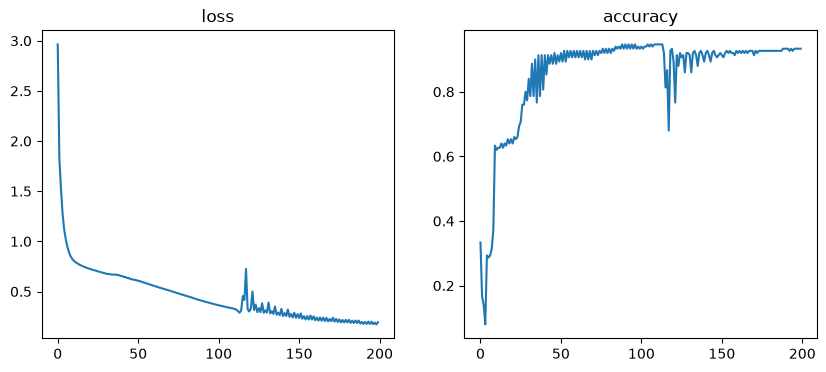

In [393]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(losses_scratch); ax1.set_title('loss')
ax2.plot(accuracy_scratch); ax2.set_title('accuracy')

8. Reimplementar la clase `RedNeuronal` utilizando PyTorch

    Hasta ahora hemos construido nuestra propia red neuronal "desde cero", lo cual nos permitió comprender en profundidad cómo funciona cada componente: inicialización de pesos, funciones de activación, forward y backward propagation, cálculo de loss y accuracy, y actualización de pesos.

    Sin embargo, en proyectos reales y más complejos, utilizamos frameworks como **PyTorch** que abstraen estas tareas, permitiéndonos enfocarnos más en el diseño de la arquitectura y el análisis de los resultados.

    **Objetivo de este inciso**: recrear la arquitectura y entrenamiento de nuestra red neuronal, pero usando herramientas provistas por PyTorch.

    > 💡 **Sugerencia pedagógica**: antes de realizar este inciso, se recomienda repasar los notebooks `9a` y `9b`, donde se presentan una introducción a los tensores y al workflow de ML usando PyTorch.

**8.1.** Implementar una clase `RedNeuronalTorch` que herede de `nn.Module` y contenga una red con la misma arquitectura:
- Entrada de dimensión 4 (por las características del dataset Iris)
- Capas ocultas de 6, 8 y 10 nodos respectivamente
- Capa de salida con 3 nodos y activación `softmax`

In [394]:
class RedNeuronalPytorch(torch.nn.Module):

    def __init__(
        self,
        input_dim: int = 4,
        n_classes: int = 3,
        learning_rate: float = 0.01,
    ) -> None:
        """
        Parameters
        ----------
        input_dim : int, default=4
            Cantidad de features de entrada.
        n_classes : int, default=3
            Neuronas de la capa de salida (la agrega `compile`).
        learning_rate : float, default=0.01
            Tasa de aprendizaje a usar en el entrenamiento.
        """
        super().__init__()

        self.lr = learning_rate
        self.n_classes = n_classes
        self._out_dim = input_dim  
        self.input_dim = input_dim
        self.layers = []


    def add(
        self,
        n_neurons: int,
        layer_clss: type[torch.nn.Module] = torch.nn.Linear,
        activ_clss: type[torch.nn.Module] = torch.nn.ReLU,
    ) -> None:
        """
        Agregar una capa oculta: layer_clss(in, n_neurons) seguida de activ_clss().

        Parameters
        ----------
        n_neurons : int
            Neuronas (out_features) de la capa.
        layer_clss : type, default=torch.nn.Linear
            Clase de la capa; se instancia con (in_features, out_features).
        activ_clss : type, default=torch.nn.ReLU
            Clase de la activación; se instancia sin argumentos.
        """
        self.layers.append(layer_clss(in_features=self._out_dim, out_features=n_neurons))
        self.layers.append(activ_clss())
        self._out_dim = n_neurons


    def compile(self) -> None:
        """
        Agregar la capa de salida (n_classes, sin activación) y armar el Sequential.

        La salida son logits: el softmax lo aplica nn.CrossEntropyLoss en el
        entrenamiento, o `predict_proba` para obtener probabilidades.
        """
        output = torch.nn.Linear(in_features=self._out_dim, out_features=self.n_classes)
        self.nn = torch.nn.Sequential(*self.layers, output)


    def init_weights_uniform(self, low: float = -1.0, high: float = 1.0) -> None:
        """
        Reinicializar los pesos igual que `RedNeuronal._init_weights`: W ~ U(low, high), b = 0.

        Reemplaza la init default de nn.Linear (Kaiming uniform, U(-1/sqrt(in), 1/sqrt(in))),
        para comparar ambas implementaciones partiendo de la misma distribución.

        Parameters
        ----------
        low : float, default=-1.0
            Límite inferior de la uniforme.
        high : float, default=1.0
            Límite superior de la uniforme.
        """
        with torch.no_grad():  # no registrar esta operación en el grafo de autograd
            for layer in self.nn:
                if isinstance(layer, torch.nn.Linear):
                    layer.weight.uniform_(low, high)
                    layer.bias.zero_()


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Pasada forward. Devuelve logits (sin softmax), que es lo que espera nn.CrossEntropyLoss.

        Parameters
        ----------
        x : torch.Tensor of shape (n_samples, input_dim)
            Datos de entrada (float32).

        Returns
        -------
        torch.Tensor of shape (n_samples, n_classes)
            Logits por clase.
        """
        return self.nn(x)

    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        """
        Probabilidades por clase: softmax sobre los logits.

        Parameters
        ----------
        x : torch.Tensor of shape (n_samples, input_dim)
            Datos de entrada (float32).

        Returns
        -------
        torch.Tensor of shape (n_samples, n_classes)
            Probabilidades por clase; cada fila suma 1.
        """
        return torch.softmax(self.forward(x), dim=1)

    def _accuracy(self, logits, y_train):
        return (logits.argmax(dim=1) == y_train).float().mean().item()

    def fit(
        self,
        X_train: torch.Tensor,
        y_train: torch.Tensor,
        epochs: int,
    ) -> tuple[list[float], list[float]]:
        """
        Entrenar el modelo con SGD full-batch (todo el dataset en cada paso, igual que RedNeuronal.train).

        Parameters
        ----------
        X_train : torch.Tensor of shape (n_samples, n_features)
            Datos de entrenamiento (float32).
        y_train : torch.Tensor of shape (n_samples,)
            Etiquetas como enteros (int64 / long), lo que espera nn.CrossEntropyLoss.
        epochs : int
            Cantidad de pasadas completas sobre los datos.

        Returns
        -------
        accuracy : list of float
            Accuracy en cada época.
        loss : list of float
            Loss en cada época.
        """

        loss_fn = torch.nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(self.parameters(), lr=self.lr)

        accuracy = []
        losses = []

        for epoch in range(epochs):
            logits = self(X_train)              # forward
            loss = loss_fn(logits, y_train)       # softmax + cross-entropy

            optimizer.zero_grad()                 # borrar gradientes de la época anterior
            loss.backward()                       # backprop (autograd)
            optimizer.step()                      # W -= lr * dW, b -= lr * db

            acc = self._accuracy(logits, y_train)
            accuracy.append(acc)

            losses.append(loss.item())

            if epoch % 20 == 0:
                print(f'EPOCH: {epoch}, ACCURACY: {acc:.4f}, LOSS: {loss.item():.4f}')

        return accuracy, losses


torch.manual_seed(99)

modelo = RedNeuronalPytorch(input_dim=4, n_classes=3, learning_rate=0.01)
modelo.add(6)
modelo.add(8)
modelo.add(10)
modelo.compile()
modelo.init_weights_uniform()  # misma init que la red scratch

modelo.nn

Sequential(
  (0): Linear(in_features=4, out_features=6, bias=True)
  (1): ReLU()
  (2): Linear(in_features=6, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=10, bias=True)
  (5): ReLU()
  (6): Linear(in_features=10, out_features=3, bias=True)
)

**8.2.** Entrenar esta nueva red por 200 épocas utilizando:
- Función de pérdida: `nn.CrossEntropyLoss`
- Optimizador: `torch.optim.SGD`
- Tasa de aprendizaje: 0.01

In [395]:
accuracy_torch, losses_torch = modelo.fit(X_t, y_t, epochs=200)

EPOCH: 0, ACCURACY: 0.3333, LOSS: 3.3318
EPOCH: 20, ACCURACY: 0.5200, LOSS: 0.8534
EPOCH: 40, ACCURACY: 0.5133, LOSS: 0.7550
EPOCH: 60, ACCURACY: 0.5267, LOSS: 0.6664
EPOCH: 80, ACCURACY: 0.9000, LOSS: 0.5375
EPOCH: 100, ACCURACY: 0.9000, LOSS: 0.4760
EPOCH: 120, ACCURACY: 0.9067, LOSS: 0.4380
EPOCH: 140, ACCURACY: 0.9333, LOSS: 0.4094
EPOCH: 160, ACCURACY: 0.9333, LOSS: 0.3857
EPOCH: 180, ACCURACY: 0.9333, LOSS: 0.3634


**8.3.** Comparar los resultados obtenidos con los del entrenamiento anterior (implementación manual). Algunas preguntas a responder:
- ¿La convergencia es más rápida o más lenta?
- ¿Cómo se comporta la pérdida durante el entrenamiento?
- ¿Cuál implementación fue más fácil de modificar o extender?

Text(0, 0.5, 'accuracy')

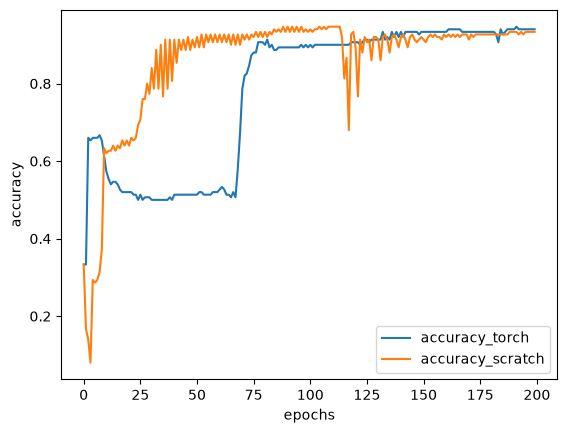

In [396]:
plt.plot(accuracy_torch, label='accuracy_torch')
plt.plot(accuracy_scratch, label='accuracy_scratch')
plt.legend()
plt.xlabel('epochs')
plt.ylabel('accuracy')

Text(0, 0.5, 'loss')

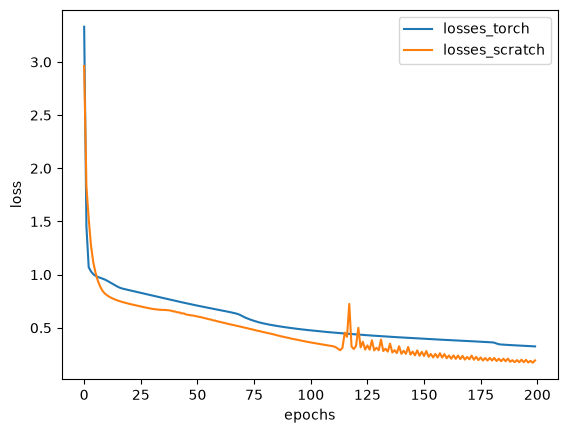

In [397]:
plt.plot(losses_torch, label='losses_torch')
plt.plot(losses_scratch, label='losses_scratch')
plt.legend()
plt.xlabel('epochs')
plt.ylabel('loss')

**8.4.** Graficar la evolución de la **pérdida** y el **accuracy** durante las épocas para ambas implementaciones (manual y PyTorch), idealmente en la misma figura para facilitar la comparación. Podés aplicar una media móvil para suavizar la señal.

Crédito: este ejercicio se base en la propuesta de Joe Sasson publicada en [Towards Data Science](https://towardsdatascience.com/coding-a-neural-network-from-scratch-in-numpy-31f04e4d605).

### Código completo (Implementación con Numpy)


In [398]:
class Capa_POSTA:
    def __init__(self, neuronas):
        self.neuronas = neuronas

    def forward(self, inputs, weights, bias, activation):
        """
        Forward Propagation de la capa
        """
        Z_curr = np.dot(inputs, weights.T) + bias

        if activation == 'relu':
            A_curr = self.relu(inputs=Z_curr)
        elif activation == 'softmax':
            A_curr = self.softmax(inputs=Z_curr)

        return A_curr, Z_curr

    def relu(self, inputs):
        """
        ReLU: función de activación
        """

        return np.maximum(0, inputs)

    def softmax(self, inputs):
        """
        Softmax: función de activación
        """
        exp_scores = np.exp(inputs)
        probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
        return probs
         
    def backward(self, dA_curr, W_curr, Z_curr, A_prev, activation):
        """
        Backward Propagation de la capa
        """
        if activation == 'softmax':
            dW = np.dot(A_prev.T, dA_curr)
            db = np.sum(dA_curr, axis=0, keepdims=True)
            dA = np.dot(dA_curr, W_curr) 
        else:
            dZ = self.relu_derivative(dA_curr, Z_curr)
            dW = np.dot(A_prev.T, dZ)
            db = np.sum(dZ, axis=0, keepdims=True)
            dA = np.dot(dZ, W_curr)
            
        return dA, dW, db

    def relu_derivative(self, dA, Z):
        """
        ReLU: gradiente de ReLU
        """
        dZ = np.array(dA, copy = True)
        dZ[Z <= 0] = 0
        return dZ
    

In [399]:
class RedNeuronal_POSTA:
    def __init__(self, learning_rate=0.01):
        self.red = [] ## capas
        self.arquitectura = [] ## mapeo de entradas -> salidas
        self.pesos = [] ## W, b
        self.memoria = [] ## Z, A
        self.gradientes = [] ## dW, db
        self.lr = learning_rate
        
    def add(self, capa):
        """
        Agregar capa a la red
        """
        self.red.append(capa)
            
    def _compile(self, data):
        """
        Inicializar la arquitectura
        """
        for idx, _ in enumerate(self.red):
            if idx == 0:
                self.arquitectura.append({'input_dim': data.shape[1], 
                                        'output_dim': self.red[idx].neuronas,
                                        'activation':'relu'})
            elif idx > 0 and idx < len(self.red)-1:
                self.arquitectura.append({'input_dim': self.red[idx-1].neuronas, 
                                        'output_dim': self.red[idx].neuronas,
                                        'activation':'relu'})
            else:
                self.arquitectura.append({'input_dim': self.red[idx-1].neuronas, 
                                        'output_dim': self.red[idx].neuronas,
                                        'activation':'softmax'})
        return self

    def _init_weights(self, data):
        """
        Inicializar arquitectura y los pesos
        """
        self._compile(data)

        np.random.seed(99)

        for i in range(len(self.arquitectura)):
            self.pesos.append({
                'W':np.random.uniform(low=-1, high=1, 
                        size=(self.arquitectura[i]['input_dim'],
                            self.arquitectura[i]['output_dim']
                            )),
                'b':np.zeros((1, self.arquitectura[i]['output_dim']))})

        return self
    
    def _forwardprop(self, data):
        """
        Pasada forward completa por la red
        """
        A_curr = data

        for i in range(len(self.pesos)):
            A_prev = A_curr
            A_curr, Z_curr = self.red[i].forward(inputs=A_prev, 
                                                    weights=self.pesos[i]['W'].T, 
                                                    bias=self.pesos[i]['b'], 
                                                    activation=self.arquitectura[i]['activation'])

            self.memoria.append({'inputs':A_prev, 'Z':Z_curr})

        return A_curr
    
    def _backprop(self, predicted, actual):
        """
        Pasada backward completa por la red
        """
        num_samples = len(actual)

        ## compute the gradient on predictions
        dscores = predicted
        dscores[range(num_samples),actual] -= 1
        dscores /= num_samples

        dA_prev = dscores

        for idx, layer in reversed(list(enumerate(self.red))):
            dA_curr = dA_prev

            A_prev = self.memoria[idx]['inputs']
            Z_curr = self.memoria[idx]['Z']
            W_curr = self.pesos[idx]['W']

            activation = self.arquitectura[idx]['activation']

            dA_prev, dW_curr, db_curr = layer.backward(dA_curr, W_curr.T, Z_curr, A_prev, activation)

            self.gradientes.append({'dW':dW_curr, 'db':db_curr})

        self.gradientes = list(reversed(self.gradientes))  # Reverse the gradients list

    def _update(self):
        """
        Actualizar el modelo --> lr * gradiente
        """
        lr = self.lr
        for idx, layer in enumerate(self.red):
            self.pesos[idx]['W'] -= lr * self.gradientes[idx]['dW']
            self.pesos[idx]['b'] -= lr * self.gradientes[idx]['db']

    def _get_accuracy(self, predicted, actual):
        """
        Calcular accuracy después de cada iteración
        """
        return np.mean(np.argmax(predicted, axis=1)==actual)
        
    def _calculate_loss(self, predicted, actual):
        """
        Calculate cross-entropy loss after each iteration
        """
        samples = len(actual)

        correct_logprobs = -np.log(predicted[range(samples),actual])
        data_loss = np.sum(correct_logprobs)/samples

        return data_loss

    def train(self, X_train, y_train, epochs):
        """
        Entrenar el modelo Stochastic Gradient Descent
        """
        self.loss = []
        self.accuracy = []

        self._init_weights(X_train)

        for i in range(epochs):

            yhat = self._forwardprop(X_train)

            self.accuracy.append(self._get_accuracy(predicted=yhat, actual=y_train))
            self.loss.append(self._calculate_loss(predicted=yhat, actual=y_train))

            self._backprop(predicted=yhat, actual=y_train)
            self._update()

            if i % 20 == 0:
                s = 'EPOCH: {}, ACCURACY: {}, LOSS: {}'.format(i, self.accuracy[-1], self.loss[-1])
                print(s)

        return (self.accuracy, self.loss)
